# Día 2 — Overfitting, Validación Cruzada, Árboles de Decisión y Random Forest

**Módulo 3: Machine Learning Aplicado — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 14-10-2026

Este notebook continúa exactamente desde el Día 1 y el Día 1.1.

En el Día 1 aprendimos:

- regresión lineal simple;
- regresión múltiple;
- MAE, MSE, RMSE, $R^2$ y Bias;
- Train, Validation y Test;
- predicción de nuevos datos.

Como lectura complementaria se dejó un notebook sobre:

- Ridge;
- Lasso;
- Elastic Net;
- regularización.

No asumiremos esos modelos como contenido ya estudiado en clase.

Hoy vamos a cerrar la **Unidad 1: Regresión y Predicción** y comenzar la **Unidad 2: Clasificación**.

## Contenido del día

### Unidad 1. Regresión y Predicción

**1.4 Overfitting**

- underfitting;
- ajuste adecuado;
- overfitting;
- comparación Train vs Validation/Test;
- relación entre complejidad y generalización.

**1.5 Validación cruzada**

- K-Fold Cross Validation;
- métricas por fold;
- promedio y desviación;
- estabilidad de un modelo.

### Unidad 2. Clasificación

**2.1 Árboles de decisión**

- cómo piensa un árbol;
- nodos, ramas y hojas;
- cómo decide dónde cortar;
- impureza de Gini;
- cómo ajustar la complejidad del árbol;
- diferencias frente a la regresión lineal;
- aplicación al dataset Bank Marketing.

**2.2 Random Forest**

- por qué un solo árbol puede ser inestable;
- bootstrap;
- múltiples árboles;
- voto;
- `n_estimators`;
- `max_depth`;
- `min_samples_leaf`.

## Dos fuentes de datos reales

En este notebook utilizaremos dos fuentes públicas:

1. **World Bank Indicators API** para cerrar la parte de regresión, overfitting y validación cruzada.
2. **UCI Bank Marketing** para clasificación con árboles.

La API del Banco Mundial no requiere API key.

Documentación oficial:

https://datahelpdesk.worldbank.org/knowledgebase/articles/889392

# 0. Librerías

No instalaremos paquetes automáticamente.

Las librerías utilizadas forman parte de una instalación habitual de Anaconda / scikit-learn.

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression

from sklearn.tree import (
    DecisionTreeRegressor,
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

# 1. Antes de comenzar: cómo controlaremos la complejidad del árbol

En el Día 1 trabajamos con regresión lineal y nos concentramos en entender cómo el modelo aprende una relación entre las variables y la predicción.

En este Día 2 aparecerá algo nuevo: los árboles pueden crecer mucho o poco dependiendo de ciertas configuraciones que nosotros decidimos.

En esta jornada simplemente utilizaremos algunas configuraciones para observar cómo cambia la complejidad del árbol:

- `max_depth`: limita cuántos niveles puede tener el árbol;
- `min_samples_split`: indica cuántas observaciones necesita un nodo para poder dividirse;
- `min_samples_leaf`: indica cuántas observaciones como mínimo debe conservar una hoja.

La idea será experimentar con estos valores y observar qué ocurre con:

- Train;
- Validation;
- underfitting;
- overfitting.

Más adelante estudiaremos formalmente cómo se denominan este tipo de configuraciones y cómo se pueden seleccionar de manera sistemática.

# 2. Datos económicos reales: World Bank Indicators API

Hasta ahora habíamos trabajado con un dataset didáctico.

Para cerrar la unidad de regresión utilizaremos datos publicados por el Banco Mundial.

La API permite consultar indicadores mediante URLs como:

```text
https://api.worldbank.org/v2/country/ECU/indicator/NY.GDP.MKTP.KD.ZG
```

y solicitar la respuesta en JSON:

```text
?format=json
```

No necesitamos usuario, contraseña ni API key.

## Indicadores que utilizaremos

| Variable | Código Banco Mundial |
|---|---|
| Crecimiento PIB (%) | `NY.GDP.MKTP.KD.ZG` |
| Inflación (%) | `FP.CPI.TOTL.ZG` |
| Desempleo (%) | `SL.UEM.TOTL.ZS` |
| Exportaciones (% PIB) | `NE.EXP.GNFS.ZS` |
| Formación bruta de capital (% PIB) | `NE.GDI.TOTL.ZS` |
| Crecimiento poblacional (%) | `SP.POP.GROW` |

Nuestro objetivo será:

> utilizar varios indicadores de una observación país-año para estimar el crecimiento anual del PIB.

Esto sigue siendo un ejercicio de **regresión supervisada**.

> No es todavía un modelo formal de series temporales ni un pronóstico macroeconómico oficial.

## 2.1 Primera consulta manual a la API

Antes de automatizar, veamos qué devuelve una petición.

Consultaremos el crecimiento del PIB de Ecuador.

La API devuelve una estructura JSON con dos elementos:

1. metadatos de la respuesta;
2. observaciones.

In [27]:
URL_DEMO = (
    'https://api.worldbank.org/v2/'
    'country/ECU/indicator/NY.GDP.MKTP.KD.ZG'
)

respuesta = requests.get(
    URL_DEMO,
    params={
        'format': 'json',
        'date': '2020:2024',
        'per_page': 100
    },
    timeout=30
)

respuesta.raise_for_status()

json_demo = respuesta.json()

print('Metadatos:')
print(json_demo[0])

print('\nPrimera observación:')
print(json_demo[1][0])

Metadatos:
{'page': 1, 'pages': 1, 'per_page': 100, 'total': 5, 'sourceid': '2', 'lastupdated': '2026-07-13'}

Primera observación:
{'indicator': {'id': 'NY.GDP.MKTP.KD.ZG', 'value': 'GDP growth (annual %)'}, 'country': {'id': 'EC', 'value': 'Ecuador'}, 'countryiso3code': 'ECU', 'date': '2024', 'value': -1.94409022506859, 'unit': '', 'obs_status': '', 'decimal': 1}


La observación contiene, entre otros elementos:

- país;
- código ISO;
- año;
- indicador;
- valor.

En Machine Learning nos interesa transformar esta respuesta JSON en una tabla.

In [28]:
demo_ecuador = pd.DataFrame([
    {
        'pais': fila['country']['value'],
        'iso3': fila['countryiso3code'],
        'anio': int(fila['date']),
        'crecimiento_pib_pct': fila['value']
    }
    for fila in json_demo[1]
])

demo_ecuador.sort_values('anio')

,pais,iso3,anio,crecimiento_pib_pct
4,Ecuador,ECU,2020,-9.245096
3,Ecuador,ECU,2021,9.421893
2,Ecuador,ECU,2022,5.868424
1,Ecuador,ECU,2023,1.832841
0,Ecuador,ECU,2024,-1.944090


## 2.2 Automatizar la descarga

En lugar de copiar una consulta para cada indicador crearemos una función.

La función:

1. recibe un código de indicador;
2. consulta varios países;
3. transforma JSON a DataFrame;
4. devuelve una tabla lista para combinar.

In [29]:
PAISES = [
    'ECU',
    'COL',
    'PER',
    'CHL',
    'ARG',
    'BRA',
    'MEX'
]

INDICADORES = {
    'crecimiento_pib_pct': 'NY.GDP.MKTP.KD.ZG',
    'inflacion_pct': 'FP.CPI.TOTL.ZG',
    'desempleo_pct': 'SL.UEM.TOTL.ZS',
    'exportaciones_pct_pib': 'NE.EXP.GNFS.ZS',
    'inversion_pct_pib': 'NE.GDI.TOTL.ZS',
    'crecimiento_poblacion_pct': 'SP.POP.GROW'
}

ANIO_INICIO = 2005
ANIO_FIN = 2024

In [30]:
def descargar_indicador_banco_mundial(
    nombre_variable,
    codigo_indicador,
    paises,
    anio_inicio,
    anio_fin
):
    paises_url = ';'.join(paises)

    url = (
        'https://api.worldbank.org/v2/'
        f'country/{paises_url}/'
        f'indicator/{codigo_indicador}'
    )

    respuesta = requests.get(
        url,
        params={
            'format': 'json',
            'date': f'{anio_inicio}:{anio_fin}',
            'per_page': 20000
        },
        timeout=30
    )

    respuesta.raise_for_status()

    contenido = respuesta.json()

    if (
        not isinstance(contenido, list)
        or len(contenido) < 2
        or contenido[1] is None
    ):
        raise ValueError(
            f'La API no devolvió datos para {codigo_indicador}'
        )

    filas = []

    for registro in contenido[1]:

        filas.append({
            'iso3': registro['countryiso3code'],
            'pais': registro['country']['value'],
            'anio': int(registro['date']),
            nombre_variable: registro['value']
        })

    return pd.DataFrame(filas)

## 2.3 Descargar y combinar los indicadores

Cada indicador viene como una tabla independiente.

Necesitamos combinarlas utilizando:

```text
país + año
```

como identificadores.

También guardaremos una copia local.

Esto es útil para una clase: si la API funcionó una vez, podremos reutilizar el archivo si posteriormente falla la conexión.

In [31]:
DATA_DIR = Path('../datos')

if not DATA_DIR.exists():
    DATA_DIR = Path('datos')

DATA_DIR.mkdir(parents=True, exist_ok=True)

CACHE_WB = DATA_DIR / 'world_bank_latam_ml.csv'

# True = intentar consultar nuevamente la API.
# False = utilizar directamente el archivo local si ya existe.
ACTUALIZAR_DESDE_API = True

In [32]:
def construir_dataset_world_bank():

    tablas = []

    for nombre, codigo in INDICADORES.items():

        print(
            'Descargando:',
            nombre,
            '|',
            codigo
        )

        tabla = descargar_indicador_banco_mundial(
            nombre_variable=nombre,
            codigo_indicador=codigo,
            paises=PAISES,
            anio_inicio=ANIO_INICIO,
            anio_fin=ANIO_FIN
        )

        tablas.append(tabla)

    df_final = tablas[0]

    for tabla in tablas[1:]:
        df_final = df_final.merge(
            tabla,
            on=['iso3', 'pais', 'anio'],
            how='outer'
        )

    return (
        df_final
        .sort_values(['iso3', 'anio'])
        .reset_index(drop=True)
    )

In [33]:
if ACTUALIZAR_DESDE_API:

    try:
        df_wb = construir_dataset_world_bank()

        df_wb.to_csv(
            CACHE_WB,
            index=False
        )

        print(
            '\nCopia local guardada en:',
            CACHE_WB
        )

    except Exception as error:

        print(
            'No fue posible actualizar desde la API.'
        )
        print(
            'Detalle:',
            error
        )

        if CACHE_WB.exists():
            print(
                '\nUsando copia local existente.'
            )
            df_wb = pd.read_csv(CACHE_WB)
        else:
            raise

else:

    if not CACHE_WB.exists():
        raise FileNotFoundError(
            'No existe la copia local. '
            'Usa ACTUALIZAR_DESDE_API = True.'
        )

    df_wb = pd.read_csv(CACHE_WB)


print('\nDimensiones:', df_wb.shape)
df_wb.head()

Descargando: crecimiento_pib_pct | NY.GDP.MKTP.KD.ZG
Descargando: inflacion_pct | FP.CPI.TOTL.ZG
Descargando: desempleo_pct | SL.UEM.TOTL.ZS
Descargando: exportaciones_pct_pib | NE.EXP.GNFS.ZS
Descargando: inversion_pct_pib | NE.GDI.TOTL.ZS
Descargando: crecimiento_poblacion_pct | SP.POP.GROW

Copia local guardada en: ..\datos\world_bank_latam_ml.csv

Dimensiones: (140, 9)


,iso3,pais,anio,crecimiento_pib_pct,inflacion_pct,desempleo_pct,exportaciones_pct_pib,inversion_pct_pib,crecimiento_poblacion_pct
0,ARG,Argentina,2005,8.851660,NaN,11.506,23.245877,18.888264,1.027458
1,ARG,Argentina,2006,8.047152,NaN,10.078,23.026695,18.680487,1.028248
2,ARG,Argentina,2007,9.007651,NaN,8.470,22.662750,20.099113,0.991102
3,ARG,Argentina,2008,4.057233,NaN,7.837,22.060900,19.572776,1.012889
4,ARG,Argentina,2009,-5.918525,NaN,8.645,19.560985,16.053112,1.059775


# 3. Conocer los datos antes de modelar

Cada fila representa:

> **un país en un año determinado**

Por ejemplo:

```text
Ecuador — 2019
Ecuador — 2020
Colombia — 2019
...
```

Nuestro target será:

```text
crecimiento_pib_pct
```

Las demás variables actuarán como predictores.

Primero revisamos:

- dimensiones;
- tipos;
- nulos;
- rango temporal;
- países.

In [34]:
print('Dimensiones:')
print(df_wb.shape)

print('\nTipos:')
print(df_wb.dtypes)

print('\nPaíses:')
print(
    sorted(
        df_wb['pais']
        .dropna()
        .unique()
    )
)

print(
    '\nRango temporal:',
    df_wb['anio'].min(),
    '-',
    df_wb['anio'].max()
)

Dimensiones:
(140, 9)

Tipos:
iso3                          object
pais                          object
anio                           int64
crecimiento_pib_pct          float64
inflacion_pct                float64
desempleo_pct                float64
exportaciones_pct_pib        float64
inversion_pct_pib            float64
crecimiento_poblacion_pct    float64
dtype: object

Países:
['Argentina', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Mexico', 'Peru']

Rango temporal: 2005 - 2024


In [35]:
nulos_wb = (
    df_wb
    .isna()
    .sum()
    .sort_values(ascending=False)
)

nulos_wb[nulos_wb > 0]

inflacion_pct    13
dtype: int64

Es normal que una fuente pública tenga valores faltantes.

No todos los países publican todos los indicadores para todos los años.

Para esta práctica utilizaremos únicamente observaciones completas en las variables seleccionadas.

En un proyecto real deberíamos investigar primero **por qué falta cada dato** antes de decidir eliminar o imputar.

In [36]:
FEATURES_WB = [
    'inflacion_pct',
    'desempleo_pct',
    'exportaciones_pct_pib',
    'inversion_pct_pib',
    'crecimiento_poblacion_pct'
]

TARGET_WB = 'crecimiento_pib_pct'

df_wb_modelo = (
    df_wb[
        [
            'iso3',
            'pais',
            'anio',
            *FEATURES_WB,
            TARGET_WB
        ]
    ]
    .dropna()
    .reset_index(drop=True)
)

print(
    'Observaciones utilizables:',
    len(df_wb_modelo)
)

df_wb_modelo.head()

Observaciones utilizables: 127


,iso3,pais,anio,inflacion_pct,desempleo_pct,exportaciones_pct_pib,inversion_pct_pib,crecimiento_poblacion_pct,crecimiento_pib_pct
0,ARG,Argentina,2018,34.277224,9.220,14.436686,16.613885,0.822969,-2.617396
1,ARG,Argentina,2019,53.548304,9.843,17.924878,14.210030,0.710901,-2.000861
2,ARG,Argentina,2020,42.015095,11.461,16.605414,14.415156,0.484666,-9.900485
3,ARG,Argentina,2021,48.409379,8.736,18.066709,18.076289,0.265879,10.441812
4,ARG,Argentina,2022,72.430758,6.805,16.281668,17.385586,0.210809,6.020745


## 3.1 ¿Qué intentaremos predecir?

Nuestro problema puede representarse como:

$$
X=
[
\text{inflación},
\text{desempleo},
\text{exportaciones},
\text{inversión},
\text{crecimiento poblacional}
]
$$

y:

$$
y=\text{crecimiento del PIB}
$$

Es una práctica didáctica de Machine Learning.

Una asociación predictiva encontrada por el modelo **no debe interpretarse automáticamente como causalidad económica**.

In [37]:
X_wb = df_wb_modelo[FEATURES_WB]
y_wb = df_wb_modelo[TARGET_WB]

X_wb.describe().round(2)

,inflacion_pct,desempleo_pct,exportaciones_pct_pib,inversion_pct_pib,crecimiento_poblacion_pct
count,127.00,127.00,127.00,127.00,127.00
mean,8.69,6.84,25.30,21.49,1.06
std,24.02,3.13,8.94,3.06,0.39
min,-0.34,2.68,10.85,14.21,0.21
25%,2.92,3.82,16.62,19.61,0.81
50%,3.81,6.76,26.51,22.03,0.99
75%,5.54,9.26,31.53,23.51,1.36
max,219.88,15.98,45.13,28.90,1.84


# 4. Underfitting, buen ajuste y overfitting

Uno de los objetivos centrales de Machine Learning no es memorizar Train.

Queremos:

> aprender patrones en Train que funcionen también con observaciones nuevas.

Existen tres situaciones importantes.

## Underfitting

El modelo es demasiado simple.

```text
Train: malo
Validation: malo
```

No logra aprender suficientemente el patrón.

## Ajuste razonable

El modelo aprende el patrón principal y generaliza.

```text
Train: bueno
Validation: parecido
```

No buscamos que ambos resultados sean idénticos, sino que la diferencia sea razonable.

## Overfitting

El modelo aprende excesivamente los detalles particulares de Train.

```text
Train: excelente
Validation: mucho peor
```

Podemos pensar que el modelo comenzó a memorizar ruido.

### Idea principal

$$
\text{más complejidad}
\not\Rightarrow
\text{mejor generalización}
$$

Un modelo puede mejorar continuamente en Train mientras empeora en datos nuevos.

# 5. Separar desarrollo y Test

Mantendremos Test aislado.

Primero reservamos aproximadamente:

- 85 % para desarrollo;
- 15 % para Test.

Dentro del conjunto de desarrollo podremos utilizar Validation y K-Fold.

Test será nuestro examen final.

In [38]:
X_dev_wb, X_test_wb, y_dev_wb, y_test_wb = train_test_split(
    X_wb,
    y_wb,
    test_size=0.15,
    random_state=42
)

print('Desarrollo:', X_dev_wb.shape)
print('Test:', X_test_wb.shape)

Desarrollo: (107, 5)
Test: (20, 5)


# 6. Validación cruzada: ¿por qué no depender de una sola división?

En el Día 1 utilizamos:

```text
Train | Validation | Test
```

Esto se conoce como **holdout**.

Es correcto, pero existe una limitación:

> ¿qué ocurre si por azar nuestro Validation resultó especialmente fácil o especialmente difícil?

Con **K-Fold Cross Validation** dividimos los datos de desarrollo en $K$ partes.

Con $K=5$:

```text
Fold 1: VALIDAR   entrenar  entrenar  entrenar  entrenar
Fold 2: entrenar  VALIDAR   entrenar  entrenar  entrenar
Fold 3: entrenar  entrenar  VALIDAR   entrenar  entrenar
Fold 4: entrenar  entrenar  entrenar  VALIDAR   entrenar
Fold 5: entrenar  entrenar  entrenar  entrenar  VALIDAR
```

Cada parte funciona una vez como Validation.

Al final obtenemos cinco resultados.

Eso nos permite calcular:

$$
\text{métrica promedio}
$$

y también:

$$
\text{desviación entre folds}
$$

La desviación nos ayuda a hablar de **estabilidad**.

Un modelo que obtiene:

```text
0.81, 0.82, 0.80, 0.81, 0.83
```

es más estable que uno que obtiene:

```text
0.30, 0.90, 0.45, 0.88, 0.20
```

aunque sus promedios pudieran parecer similares.

## 6.1 K-Fold con regresión lineal

Utilizaremos:

```python
KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
```

- `n_splits=5`: cinco folds;
- `shuffle=True`: mezcla las filas antes de dividir;
- `random_state=42`: hace reproducible esa mezcla.

> Esto es K-Fold estándar sobre observaciones país-año. Si el objetivo fuera un forecasting temporal estricto, utilizaríamos una estrategia temporal como `TimeSeriesSplit` en lugar de mezclar años.

In [39]:
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

modelo_lineal_wb = LinearRegression()

cv_lineal = cross_validate(
    modelo_lineal_wb,
    X_dev_wb,
    y_dev_wb,
    cv=kfold,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'MSE': 'neg_mean_squared_error',
        'R2': 'r2'
    },
    return_train_score=True
)

Scikit-learn convierte MAE y MSE en valores negativos dentro de `scoring`.

La razón es que la biblioteca utiliza una convención:

> **un score mayor siempre debe representar algo mejor**.

Como un error menor es mejor, Scikit-learn utiliza su negativo.

Para interpretarlo normalmente debemos volver a cambiar el signo.

In [40]:
tabla_cv_lineal = pd.DataFrame({
    'fold': np.arange(1, 6),

    'MAE_train':
        -cv_lineal['train_MAE'],

    'MAE_validation':
        -cv_lineal['test_MAE'],

    'RMSE_train':
        np.sqrt(
            -cv_lineal['train_MSE']
        ),

    'RMSE_validation':
        np.sqrt(
            -cv_lineal['test_MSE']
        ),

    'R2_train':
        cv_lineal['train_R2'],

    'R2_validation':
        cv_lineal['test_R2']
})

tabla_cv_lineal.round(3)

,fold,MAE_train,MAE_validation,RMSE_train,RMSE_validation,R2_train,R2_validation
0,1,3.034,2.191,4.131,2.747,0.117,0.311
1,2,2.566,4.078,3.455,5.231,0.162,0.093
2,3,3.004,2.624,3.989,3.500,0.167,-0.065
3,4,3.111,2.264,4.111,2.941,0.166,-0.444
4,5,2.599,3.814,3.559,5.063,0.159,0.087


In [41]:
resumen_cv_lineal = pd.DataFrame({
    'promedio': [
        tabla_cv_lineal['MAE_validation'].mean(),
        tabla_cv_lineal['RMSE_validation'].mean(),
        tabla_cv_lineal['R2_validation'].mean()
    ],
    'desviacion': [
        tabla_cv_lineal['MAE_validation'].std(),
        tabla_cv_lineal['RMSE_validation'].std(),
        tabla_cv_lineal['R2_validation'].std()
    ]
}, index=[
    'MAE',
    'RMSE',
    'R2'
])

resumen_cv_lineal.round(3)

,promedio,desviacion
MAE,2.994,0.889
RMSE,3.896,1.176
R2,-0.004,0.281


## ¿Cómo interpretar la desviación?

**Observación en esta ejecución:** los cinco MAE de Validation van aproximadamente de 2,19 a 4,08 **puntos porcentuales de crecimiento del PIB**. El promedio es 2,99 y la desviación es 0,89; no se trata de un error constante entre particiones. Si vuelves a descargar datos de la API, usa los valores de tu tabla, no estos como referencia fija.

El $R^2$ promedio de Validation es aproximadamente −0,004, con folds negativos. Un $R^2$ negativo indica que, en ese fold, el error cuadrático supera la referencia matemática de predecir siempre la **media observada del propio fold de Validation**. Esa media no estaría disponible al predecir; para comparar modelos de forma operativa deberíamos entrenar un baseline con la media de Train. No significa que el PIB sea negativo ni que el modelo esté roto: indica que esta regresión lineal no demuestra una ventaja predictiva estable con estas variables y particiones.

**Diagnóstico:** mira juntos MAE, RMSE y $R^2$. RMSE penaliza más los errores grandes; la dispersión entre folds advierte que una sola división podría dar una impresión demasiado favorable. K-Fold aleatorio aquí es un ejercicio metodológico con observaciones país-año: si la pregunta fuera predecir años futuros, separaríamos cronológicamente y evitaríamos mezclar años del mismo país entre pasado y futuro.

**Para discutir:** ¿cambiaría tu conclusión si solo hubieras visto el fold con menor MAE? ¿Qué baseline y qué diseño temporal exigirías antes de usar el modelo para pronosticar?

# 7. Antes de programar un árbol: ¿qué es un árbol de decisión?

Hasta ahora nuestra regresión lineal buscaba una ecuación:

$$
\hat y=
b_0+b_1x_1+\cdots+b_px_p
$$

Un árbol piensa de manera completamente diferente.

No construye una única ecuación global.

Construye una secuencia de preguntas.

Por ejemplo:

```text
¿desempleo <= 7.5?
        |
   ┌────┴────┐
  Sí         No
  |           |
¿inflación   ¿inversión
 <= 4?        <= 20?
```

Cada pregunta divide las observaciones.

## Partes de un árbol

### Nodo raíz

Es la primera pregunta.

### Nodo interno

Es una pregunta intermedia.

### Rama

Representa una respuesta a una pregunta.

### Hoja

Es el final del camino y contiene la predicción.

Un dato nuevo entra por la raíz y recorre un único camino hasta una hoja.

# 8. Regresión lineal vs árbol

| Aspecto | Regresión lineal | Árbol |
|---|---|---|
| Forma del modelo | Ecuación | Reglas sucesivas |
| Relación | Principalmente lineal | Puede aprender relaciones no lineales |
| Escalado | Puede ser importante en algunos modelos | Generalmente no necesario |
| Interacciones | Debemos modelarlas explícitamente | Puede encontrarlas mediante ramas |
| Predicción | Combinación de coeficientes | Valor/clase de una hoja |
| Complejidad | Relativamente controlada | Puede crecer mucho |
| Riesgo de overfitting | Existe | Muy visible si el árbol crece sin límite |
| Interpretabilidad | Coeficientes | Reglas y caminos |

## Un árbol también puede hacer regresión

Si el target es numérico:

```text
crecimiento PIB = 3.2
```

podemos utilizar:

```python
DecisionTreeRegressor
```

Una hoja de regresión normalmente predice un valor como la **media de las observaciones que llegaron a esa hoja**.

## Y también puede hacer clasificación

Si el target es una clase:

```text
sí / no
```

utilizamos:

```python
DecisionTreeClassifier
```

En ese caso la hoja trabaja con clases y probabilidades.

# 9. ¿Cómo decide un árbol dónde cortar?

Un árbol prueba posibles preguntas.

Por ejemplo:

```text
inflacion <= 3.2
inflacion <= 3.7
inflacion <= 4.1
...
```

y hace algo parecido con las demás variables.

Después intenta encontrar la división que produzca grupos más “puros” o más homogéneos.

El criterio depende del tipo de árbol.

## En regresión

Podemos utilizar reducción de error cuadrático.

Queremos que dentro de una hoja los valores de $y$ sean lo más parecidos posible.

## En clasificación

Podemos utilizar **impureza de Gini**.

Para dos clases:

$$
Gini
=
1-
(p_0^2+p_1^2)
$$

Una hoja completamente pura:

```text
NO NO NO NO NO
```

tiene:

$$
Gini=0
$$

porque solamente existe una clase.

## 9.1 Cálculo manual de Gini

Supongamos un nodo con 10 clientes:

```text
6 NO
4 SÍ
```

Entonces:

$$
p(NO)=\frac{6}{10}=0.6
$$

$$
p(SÍ)=\frac{4}{10}=0.4
$$

Por tanto:

$$
Gini
=
1-(0.6^2+0.4^2)
$$

$$
Gini
=
1-(0.36+0.16)
$$

$$
Gini=0.48
$$

Ahora imaginemos una pregunta:

> ¿contactos previos <= 1?

y produce:

### Rama izquierda

```text
5 NO
0 SÍ
```

$$
Gini_{izq}=0
$$

### Rama derecha

```text
1 NO
4 SÍ
```

$$
Gini_{der}
=
1-(0.2^2+0.8^2)
=
0.32
$$

Como ambas ramas tienen 5 observaciones:

$$
Gini_{ponderado}
=
\frac{5}{10}(0)
+
\frac{5}{10}(0.32)
$$

$$
Gini_{ponderado}=0.16
$$

Antes del corte teníamos:

$$
0.48
$$

Después:

$$
0.16
$$

La impureza disminuyó considerablemente.

Ese tipo de reducción es lo que busca el árbol al escoger una división.

# 10. Ajustes que controlan la complejidad del árbol

Un árbol sin límites puede seguir creando ramas hasta aprender detalles demasiado específicos de Train.

Para controlar cuánto puede crecer utilizaremos tres configuraciones principales.

## `max_depth`

Indica la profundidad máxima del árbol.

```python
max_depth=2
```

produce un árbol pequeño.

```python
max_depth=None
```

permite que el árbol continúe creciendo mientras existan divisiones posibles.

## `min_samples_split`

Indica cuántas observaciones como mínimo debe tener un nodo para poder intentar dividirse.

Por ejemplo:

```python
min_samples_split=20
```

significa que un nodo con menos de 20 observaciones ya no podrá seguir dividiéndose.

## `min_samples_leaf`

Indica cuántas observaciones como mínimo debe conservar una hoja.

Por ejemplo:

```python
min_samples_leaf=10
```

evita que el árbol cree hojas extremadamente pequeñas.

Una hoja con una o muy pocas observaciones puede representar una regla demasiado específica.

## ¿Qué ocurre cuando cambiamos estos valores?

```text
Árbol demasiado limitado
→ puede aparecer underfitting

Árbol con complejidad razonable
→ puede generalizar mejor

Árbol casi sin límites
→ aumenta el riesgo de overfitting
```

En esta unidad utilizaremos estas configuraciones de forma experimental.

Más adelante estudiaremos formalmente cómo se clasifican y cómo se seleccionan de manera sistemática.

# 11. Demostración: underfitting y overfitting con un árbol de regresión

Ahora sí vamos a programarlo.

Usaremos los datos del Banco Mundial.

Primero dividiremos el conjunto de desarrollo en:

- Train;
- Validation.

Test sigue sin tocarse.

In [42]:
X_train_wb, X_val_wb, y_train_wb, y_val_wb = train_test_split(
    X_dev_wb,
    y_dev_wb,
    test_size=0.1765,
    random_state=42
)

print('Train:', X_train_wb.shape)
print('Validation:', X_val_wb.shape)
print('Test:', X_test_wb.shape)

Train: (88, 5)
Validation: (19, 5)
Test: (20, 5)


In [43]:
def metricas_regresion(
    y_real,
    y_pred
):
    mse = mean_squared_error(
        y_real,
        y_pred
    )

    return {
        'MAE':
            mean_absolute_error(
                y_real,
                y_pred
            ),

        'RMSE':
            np.sqrt(mse),

        'R2':
            r2_score(
                y_real,
                y_pred
            )
    }

Construiremos tres árboles.

### Árbol A — muy simple

```python
max_depth=1
```

Candidato a **underfitting**.

### Árbol B — complejidad intermedia

```python
max_depth=4
```

### Árbol C — sin límite explícito de profundidad

```python
max_depth=None
```

Candidato a **overfitting**.

In [44]:
configuraciones_arbol = [
    {
        'modelo': 'Muy simple',
        'max_depth': 1
    },
    {
        'modelo': 'Intermedio',
        'max_depth': 4
    },
    {
        'modelo': 'Sin límite',
        'max_depth': None
    }
]

resultados_arbol_reg = []

modelos_arbol_reg = {}

for config in configuraciones_arbol:

    modelo = DecisionTreeRegressor(
        max_depth=config['max_depth'],
        random_state=42
    )

    modelo.fit(
        X_train_wb,
        y_train_wb
    )

    modelos_arbol_reg[
        config['modelo']
    ] = modelo

    pred_train = modelo.predict(
        X_train_wb
    )

    pred_val = modelo.predict(
        X_val_wb
    )

    met_train = metricas_regresion(
        y_train_wb,
        pred_train
    )

    met_val = metricas_regresion(
        y_val_wb,
        pred_val
    )

    resultados_arbol_reg.append({
        'modelo':
            config['modelo'],

        'max_depth':
            str(config['max_depth']),

        'MAE_train':
            met_train['MAE'],

        'MAE_validation':
            met_val['MAE'],

        'RMSE_train':
            met_train['RMSE'],

        'RMSE_validation':
            met_val['RMSE'],

        'R2_train':
            met_train['R2'],

        'R2_validation':
            met_val['R2']
    })

tabla_overfitting = pd.DataFrame(
    resultados_arbol_reg
)

tabla_overfitting.round(3)

,modelo,max_depth,MAE_train,MAE_validation,RMSE_train,RMSE_validation,R2_train,R2_validation
0,Muy simple,1,2.966,2.413,4.109,3.005,0.101,0.259
1,Intermedio,4,2.150,3.182,3.278,4.073,0.428,-0.361
2,Sin límite,None,0.000,3.523,0.000,4.950,1.000,-1.010


## ¿Qué debemos buscar?

**Leer la tabla de esta ejecución, fila por fila:**

- **Profundidad 1:** MAE Train ≈ 2,97 y Validation ≈ 2,41; $R^2$ Train ≈ 0,10 y Validation ≈ 0,26. Aprende poco incluso en Train: es candidato a *underfitting*. Que Validation salga mejor que Train en esta muestra pequeña puede ocurrir por la composición del split; no es evidencia de que validar mejore el entrenamiento.
- **Profundidad 4:** mejora Train (MAE ≈ 2,15), pero Validation empeora (MAE ≈ 3,18 y $R^2$ ≈ −0,36). Ya aparece una brecha de generalización.
- **Sin límite:** MAE Train = 0 y $R^2$ Train = 1; en Validation el MAE ≈ 3,52 y $R^2$ ≈ −1,01. Memorizar estas observaciones no significa predecir bien otras.

**Decisión provisional:** de estas tres configuraciones, la profundidad 1 tiene el menor MAE en este Validation; no escogeríamos el árbol sin límite por su perfección en Train. Eso **no prueba** que profundidad 1 sea universalmente óptima ni que el modelo sea útil: la muestra es pequeña y aún falta contrastarlo con un baseline y con validación repetida.

**Pregunta de diagnóstico:** ¿qué variable mirarías primero si Train mejora pero Validation empeora? ¿Por qué un $R^2$ de Validation negativo es una señal más fuerte que decir solamente «hay brecha»?

In [45]:
tabla_overfitting['brecha_R2'] = (
    tabla_overfitting['R2_train']
    -
    tabla_overfitting['R2_validation']
)

tabla_overfitting[
    [
        'modelo',
        'max_depth',
        'R2_train',
        'R2_validation',
        'brecha_R2'
    ]
].round(3)

,modelo,max_depth,R2_train,R2_validation,brecha_R2
0,Muy simple,1,0.101,0.259,-0.158
1,Intermedio,4,0.428,-0.361,0.789
2,Sin límite,None,1.000,-1.010,2.010


# 12. K-Fold también nos ayuda a evaluar el árbol

Ahora podemos comparar la estabilidad de:

- regresión lineal;
- árbol de profundidad controlada.

Utilizaremos exactamente los mismos cinco folds.

In [46]:
arbol_reg_cv = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=3,
    random_state=42
)

cv_arbol = cross_validate(
    arbol_reg_cv,
    X_dev_wb,
    y_dev_wb,
    cv=kfold,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'MSE': 'neg_mean_squared_error',
        'R2': 'r2'
    }
)

tabla_cv_arbol = pd.DataFrame({
    'fold': np.arange(1, 6),
    'MAE':
        -cv_arbol['test_MAE'],
    'RMSE':
        np.sqrt(
            -cv_arbol['test_MSE']
        ),
    'R2':
        cv_arbol['test_R2']
})

tabla_cv_arbol.round(3)

,fold,MAE,RMSE,R2
0,1,3.424,4.200,-0.610
1,2,3.962,5.083,0.143
2,3,4.075,5.213,-1.362
3,4,2.591,3.368,-0.894
4,5,4.141,5.419,-0.046


In [47]:
comparacion_estabilidad = pd.DataFrame({
    'modelo': [
        'Regresión lineal',
        'Árbol regresión'
    ],

    'MAE_promedio': [
        tabla_cv_lineal[
            'MAE_validation'
        ].mean(),

        tabla_cv_arbol[
            'MAE'
        ].mean()
    ],

    'MAE_std': [
        tabla_cv_lineal[
            'MAE_validation'
        ].std(),

        tabla_cv_arbol[
            'MAE'
        ].std()
    ],

    'R2_promedio': [
        tabla_cv_lineal[
            'R2_validation'
        ].mean(),

        tabla_cv_arbol[
            'R2'
        ].mean()
    ],

    'R2_std': [
        tabla_cv_lineal[
            'R2_validation'
        ].std(),

        tabla_cv_arbol[
            'R2'
        ].std()
    ]
})

comparacion_estabilidad.round(3)

,modelo,MAE_promedio,MAE_std,R2_promedio,R2_std
0,Regresión lineal,2.994,0.889,-0.004,0.281
1,Árbol regresión,3.639,0.650,-0.554,0.616


**Comparación de esta ejecución:** la regresión lineal obtiene MAE promedio ≈ 2,99 frente a ≈ 3,64 del árbol; su $R^2$ promedio es ≈ −0,00 frente a ≈ −0,55. El árbol de profundidad 4 no supera aquí a la regresión lineal. Ambos modelos muestran folds con $R^2$ negativo: no basta con escoger «el menos malo» para afirmar que existe capacidad predictiva útil.

**Matiz importante:** el árbol de esta comparación usa `min_samples_leaf=3`, mientras que el árbol de profundidad 4 de la tabla anterior usó el valor por defecto. Por ello sus métricas no son directamente intercambiables. Además, el árbol tiene menor desviación de MAE (≈ 0,65 frente a 0,89), pero mayor dispersión de $R^2$ (≈ 0,62 frente a 0,28): «más estable» depende de la métrica elegida.

**Para discutir:** si el costo de un error se expresa en puntos porcentuales de crecimiento, ¿qué columna usarías para defender la decisión? ¿Qué baseline faltaría calcular antes de recomendar uno de los dos modelos?

# 13. Cambio de problema: de regresión a clasificación

Hasta este punto nuestro target era un número:

```text
crecimiento PIB = 2.8 %
```

Eso es **regresión**.

Ahora cambiaremos a un target categórico:

```text
¿el cliente contratará un depósito a plazo?

SÍ
NO
```

Eso es **clasificación**.

Utilizaremos el dataset público:

**Bank Marketing — UCI Machine Learning Repository**

https://archive.ics.uci.edu/dataset/222/bank+marketing

El objetivo oficial del dataset es predecir si un cliente contratará un depósito a plazo después de una campaña de marketing bancario.

# 14. Cargar Bank Marketing desde datos/

El archivo oficial de UCI ya está incluido en este repositorio:

```text
datos/bank_marketing_uci.csv
```

Se lee directamente, sin necesidad de descargarlo ni de acceder a internet. El CSV original utiliza punto y coma como separador.

In [48]:
ARCHIVO_BANK = DATA_DIR / 'bank_marketing_uci.csv'

In [49]:
def cargar_bank_marketing():

    if not ARCHIVO_BANK.exists():
        raise FileNotFoundError(
            f'No se encontró {ARCHIVO_BANK.resolve()}. '
            'Descarga la carpeta datos/ junto con el notebook.'
        )

    print('Usando archivo local:', ARCHIVO_BANK)
    return pd.read_csv(ARCHIVO_BANK, sep=';')

In [50]:
bank = cargar_bank_marketing()

print('Dimensiones:', bank.shape)

bank.head()

Usando archivo local: ..\datos\bank_marketing_uci.csv
Dimensiones: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


# 15. Entender Bank Marketing antes de entrenar

Cada fila representa una observación de una campaña de marketing.

La variable:

```text
y
```

es nuestro target.

Sus valores son:

```text
yes
no
```

Primero analizamos:

- dimensiones;
- tipos;
- distribución de clases;
- valores faltantes.

In [51]:
print(bank.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [52]:
bank['y'].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

In [53]:
(
    bank['y']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

y
no     88.73
yes    11.27
Name: proportion, dtype: float64

## 15.1 El problema del desbalance

**¿Qué nos dicen los resultados que acabamos de obtener?** Hay 36 548 casos `no` y 4 640 casos `yes`: aproximadamente **88,73 % / 11,27 %**. En esta ejecución no se observan nulos de Pandas en las 21 columnas; aun así, categorías como `unknown` pueden representar información desconocida y merecen revisión.

Un clasificador que responda siempre `no` tendría cerca de **88,73 % de Accuracy** sin detectar ni un solo `yes`. Ese es nuestro **baseline de clase mayoritaria** para interpretar las Accuracy posteriores: superarlo por poco no garantiza utilidad.

Imaginemos:

```text
90 NO
10 SÍ
```

Un modelo absurdo que siempre diga:

```text
NO
```

obtendría:

$$
Accuracy=90\%
$$

pero sería inútil para detectar clientes que sí contratarían. En este dataset, el mismo problema ocurre incluso si el porcentaje de Accuracy parece cercano al 90 %.

Por eso utilizaremos también:

- **Precision**;
- **Recall**;
- **F1**.

La teoría completa de métricas de clasificación se profundizará posteriormente, pero hoy las necesitamos para comparar nuestros árboles. **Pregunta:** si queremos encontrar posibles suscriptores, ¿qué riesgo tiene un Recall muy bajo aunque Accuracy sea alta?

## 15.2 Una variable problemática: `duration`

El dataset contiene:

```text
duration
```

que representa la duración de la última llamada.

Es extremadamente predictiva.

Sin embargo, si nuestro objetivo es decidir **antes de realizar la llamada** qué cliente tiene mayor probabilidad de aceptar, todavía no conocemos cuánto durará esa llamada.

Utilizarla introduciría información que no estaría disponible en el momento real de predicción.

Eso es un excelente ejemplo de **data leakage**.

Por esta razón la excluiremos del modelo.

In [54]:
X_bank = bank.drop(
    columns=[
        'y',
        'duration'
    ]
)

y_bank = (
    bank['y']
    .eq('yes')
    .astype(int)
)

print('X:', X_bank.shape)
print('y:', y_bank.shape)

X: (41188, 19)
y: (41188,)


# 16. Variables numéricas y categóricas

Los árboles pueden trabajar perfectamente con números.

Pero Scikit-learn no acepta directamente textos como:

```text
admin.
blue-collar
married
single
```

Por eso utilizaremos One-Hot Encoding para las variables categóricas.

No necesitamos `StandardScaler` para un árbol.

El árbol compara valores mediante umbrales y el cambio de escala no modifica el orden de las observaciones.

In [55]:
columnas_numericas_bank = (
    X_bank
    .select_dtypes(
        include='number'
    )
    .columns
    .tolist()
)

columnas_categoricas_bank = (
    X_bank
    .select_dtypes(
        exclude='number'
    )
    .columns
    .tolist()
)

print(
    'Numéricas:',
    columnas_numericas_bank
)

print(
    '\nCategóricas:',
    columnas_categoricas_bank
)

Numéricas: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [56]:
def crear_preprocesador_bank():

    return ColumnTransformer(
        transformers=[
            (
                'num',
                'passthrough',
                columnas_numericas_bank
            ),
            (
                'cat',
                OneHotEncoder(
                    handle_unknown='ignore'
                ),
                columnas_categoricas_bank
            )
        ]
    )

# 17. Train, Validation y Test para clasificación

Utilizaremos nuevamente:

```text
70 % Train
15 % Validation
15 % Test
```

Pero aparece un concepto nuevo:

```python
stratify=y
```

Esto intenta conservar aproximadamente la misma proporción de:

```text
SÍ / NO
```

en cada subconjunto.

Es especialmente útil cuando las clases están desbalanceadas.

In [57]:
X_train_b, X_temp_b, y_train_b, y_temp_b = train_test_split(
    X_bank,
    y_bank,
    test_size=0.30,
    random_state=42,
    stratify=y_bank
)

X_val_b, X_test_b, y_val_b, y_test_b = train_test_split(
    X_temp_b,
    y_temp_b,
    test_size=0.50,
    random_state=42,
    stratify=y_temp_b
)

print(
    'Train:',
    X_train_b.shape
)

print(
    'Validation:',
    X_val_b.shape
)

print(
    'Test:',
    X_test_b.shape
)

Train: (28831, 19)
Validation: (6178, 19)
Test: (6179, 19)


In [58]:
def metricas_clasificacion(
    y_real,
    y_pred
):
    return {
        'Accuracy':
            accuracy_score(
                y_real,
                y_pred
            ),

        'Precision':
            precision_score(
                y_real,
                y_pred,
                zero_division=0
            ),

        'Recall':
            recall_score(
                y_real,
                y_pred,
                zero_division=0
            ),

        'F1':
            f1_score(
                y_real,
                y_pred,
                zero_division=0
            )
    }

# 18. Primer árbol de clasificación: sin limitar

Comenzaremos deliberadamente con un árbol casi sin restricciones.

```python
DecisionTreeClassifier(
    random_state=42
)
```

Queremos observar qué ocurre cuando permitimos al árbol crecer demasiado.

In [59]:
arbol_libre = Pipeline([
    (
        'prep',
        crear_preprocesador_bank()
    ),
    (
        'model',
        DecisionTreeClassifier(
            random_state=42
        )
    )
])

arbol_libre.fit(
    X_train_b,
    y_train_b
)

pred_arbol_train = (
    arbol_libre.predict(
        X_train_b
    )
)

pred_arbol_val = (
    arbol_libre.predict(
        X_val_b
    )
)

pd.DataFrame({
    'Train':
        metricas_clasificacion(
            y_train_b,
            pred_arbol_train
        ),

    'Validation':
        metricas_clasificacion(
            y_val_b,
            pred_arbol_val
        )
}).T.round(3)

,Accuracy,Precision,Recall,F1
Train,0.996,0.999,0.967,0.983
Validation,0.842,0.322,0.368,0.343


**En esta ejecución:** Train alcanza Accuracy ≈ 0,996 y F1 ≈ 0,983, pero en Validation cae a Accuracy ≈ 0,842 y F1 ≈ 0,343. La brecha de F1, de unos **0,64 puntos**, es mucho más reveladora que mirar únicamente Accuracy.

```text
memoriza Train
↓
no generaliza igual
↓
overfitting
```

En Validation, Precision ≈ 0,322 significa que, entre quienes el árbol marcó `yes`, solo alrededor del 32 % eran `yes`; Recall ≈ 0,368 significa que detectó alrededor del 37 % de los verdaderos `yes`. Además, Accuracy 0,842 queda por debajo del baseline mayoritario cercano a 0,887. **Conclusión:** este árbol sin límites no es defendible por su resultado de Train.

**Para discutir:** ¿qué costaría más en una campaña real: contactar a alguien que no contrata o no detectar a alguien que sí contrataría? La respuesta determina si priorizamos Precision o Recall. Ahora limitaremos el crecimiento del árbol.

# 19. Controlar el árbol

Probemos diferentes niveles de complejidad.

Mantendremos Test completamente fuera de esta decisión.

In [60]:
configuraciones_tree = [
    {
        'nombre': 'Muy pequeño',
        'max_depth': 2,
        'min_samples_leaf': 100
    },
    {
        'nombre': 'Intermedio',
        'max_depth': 5,
        'min_samples_leaf': 30
    },
    {
        'nombre': 'Más flexible',
        'max_depth': 10,
        'min_samples_leaf': 10
    },
    {
        'nombre': 'Sin profundidad',
        'max_depth': None,
        'min_samples_leaf': 1
    }
]

resultados_tree = []

modelos_tree = {}

for config in configuraciones_tree:

    modelo = Pipeline([
        (
            'prep',
            crear_preprocesador_bank()
        ),
        (
            'model',
            DecisionTreeClassifier(
                max_depth=
                    config[
                        'max_depth'
                    ],
                min_samples_leaf=
                    config[
                        'min_samples_leaf'
                    ],
                random_state=42
            )
        )
    ])

    modelo.fit(
        X_train_b,
        y_train_b
    )

    pred_train = modelo.predict(
        X_train_b
    )

    pred_val = modelo.predict(
        X_val_b
    )

    met_train = (
        metricas_clasificacion(
            y_train_b,
            pred_train
        )
    )

    met_val = (
        metricas_clasificacion(
            y_val_b,
            pred_val
        )
    )

    resultados_tree.append({
        'modelo':
            config['nombre'],

        'max_depth':
            str(
                config[
                    'max_depth'
                ]
            ),

        'min_samples_leaf':
            config[
                'min_samples_leaf'
            ],

        'Accuracy_train':
            met_train['Accuracy'],

        'Accuracy_val':
            met_val['Accuracy'],

        'Recall_val':
            met_val['Recall'],

        'F1_val':
            met_val['F1']
    })

    modelos_tree[
        config['nombre']
    ] = modelo


pd.DataFrame(
    resultados_tree
).round(3)

,modelo,max_depth,min_samples_leaf,Accuracy_train,Accuracy_val,Recall_val,F1_val
0,Muy pequeño,2,100,0.899,0.900,0.178,0.287
1,Intermedio,5,30,0.903,0.900,0.250,0.361
2,Más flexible,10,10,0.911,0.898,0.280,0.383
3,Sin profundidad,None,1,0.996,0.842,0.368,0.343


**Leamos los cuatro casos de esta ejecución:** el árbol muy pequeño obtiene F1 ≈ 0,287 y Recall ≈ 0,178; el intermedio, F1 ≈ 0,361 y Recall ≈ 0,250; el más flexible, F1 ≈ 0,383 y Recall ≈ 0,280. El árbol sin restricciones eleva Recall a ≈ 0,368, pero su F1 baja a ≈ 0,343 y su Accuracy cae a ≈ 0,842.

Accuracy ≈ 0,900 en los árboles pequeños parece alta, pero el baseline de responder siempre `no` ya rondaba 0,887. **Interpretación:** los modelos siguen perdiendo muchos `yes`. Si priorizamos F1 entre estas cuatro configuraciones, escogeríamos provisionalmente el árbol **más flexible**; si priorizamos no perder oportunidades, hay que estudiar Recall y el costo de falsas alarmas. El árbol intermedio de la siguiente visualización se usa para **aprender a leer ramas**, no porque haya ganado esta comparación.

**Diagnóstico:** compara Train y Validation, luego Recall/F1 y finalmente el baseline. ¿Qué modelo escogerías si contactar a un cliente adicional es barato? ¿Y si es costoso? No uses Test para resolver esta elección.

# 20. Visualizar cómo piensa un árbol

Vamos a visualizar las primeras ramas del modelo intermedio.

Aunque internamente tenga más niveles, limitaremos el gráfico a tres para que sea legible.

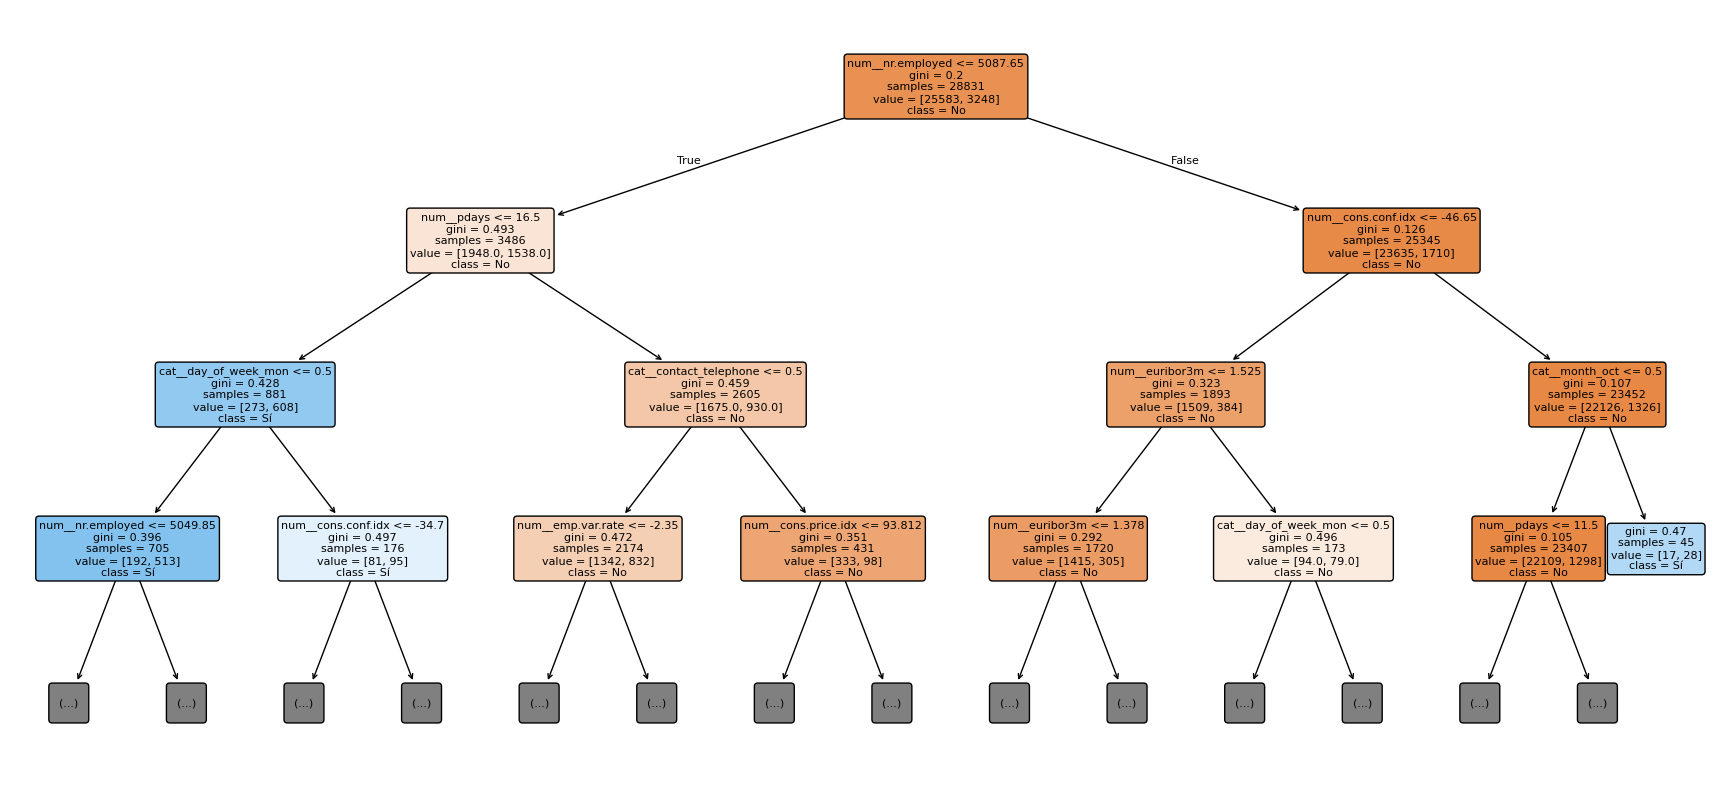

In [61]:
arbol_intermedio = (
    modelos_tree[
        'Intermedio'
    ]
)

preprocesador_entrenado = (
    arbol_intermedio
    .named_steps['prep']
)

modelo_tree_entrenado = (
    arbol_intermedio
    .named_steps['model']
)

nombres_features = (
    preprocesador_entrenado
    .get_feature_names_out()
)

plt.figure(
    figsize=(22, 10)
)

plot_tree(
    modelo_tree_entrenado,
    feature_names=nombres_features,
    class_names=[
        'No',
        'Sí'
    ],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.show()

## ¿Cómo leer un nodo?

Un nodo suele mostrar información como:

```text
variable <= umbral
gini = ...
samples = ...
value = [...]
class = ...
```

### `variable <= umbral`

Pregunta que realiza el árbol.

### `gini`

Impureza del nodo.

### `samples`

Cantidad de observaciones de entrenamiento que llegaron allí.

### `value`

Cantidad de observaciones de cada clase.

### `class`

Clase que el árbol elegiría en ese nodo/hoja.

Para predecir un cliente nuevo solamente debemos seguir las preguntas desde la raíz hasta una hoja.

# 21. Matriz de confusión del árbol

La matriz de confusión nos permite ver cuatro situaciones:

```text
Verdadero negativo
Falso positivo
Falso negativo
Verdadero positivo
```

Para una campaña bancaria, un falso negativo significa que el modelo clasificó como `NO` a un cliente que realmente terminó contratando.

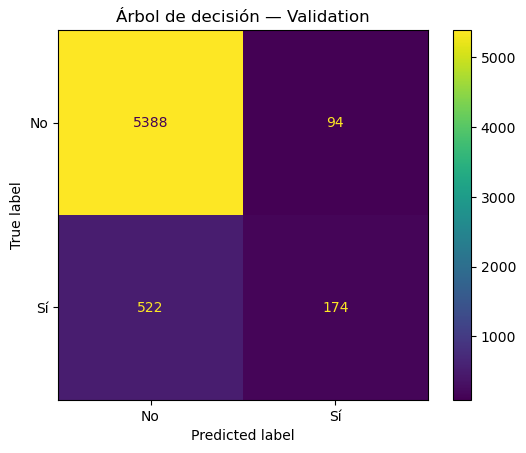

In [62]:
pred_intermedio_val = (
    arbol_intermedio
    .predict(
        X_val_b
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val_b,
    pred_intermedio_val,
    display_labels=[
        'No',
        'Sí'
    ]
)

plt.title(
    'Árbol de decisión — Validation'
)

plt.show()

# 22. ¿Por qué un solo árbol puede ser inestable?

**Antes de pasar al bosque, lee la matriz de confusión anterior:** las filas son las clases reales (`No`, `Sí`) y las columnas las predicciones. Arriba a la derecha están los falsos positivos: clientes contactados que no suscribirían. Abajo a la izquierda, los falsos negativos: clientes que sí suscribirían y el árbol deja pasar.

En este Validation, el árbol intermedio tiene Recall ≈ 0,250: detecta aproximadamente **uno de cada cuatro** `yes` y deja sin detectar los otros tres. Su Precision ≈ 0,649 indica que, de los casos que marca `yes`, alrededor del 65 % realmente lo son. **Pregunta:** si el objetivo fuera maximizar captación, ¿sería aceptable perder tres de cada cuatro oportunidades? Antes de afirmar que el modelo sirve, hay que definir el costo de ambas clases de error.

Un árbol toma decisiones jerárquicas.

Una pequeña variación en los datos puede cambiar:

- la primera división;
- las divisiones siguientes;
- la estructura completa.

Por eso un solo árbol puede tener **alta varianza**.

Una solución es no confiar en un solo árbol.

Podemos entrenar muchos.

Aquí aparece:

# Random Forest

# 23. ¿Cómo funciona Random Forest?

Random Forest construye muchos árboles y combina sus decisiones.

Simplificando:

```text
Dataset
   |
   ├── muestra bootstrap → Árbol 1
   ├── muestra bootstrap → Árbol 2
   ├── muestra bootstrap → Árbol 3
   ├── ...
   └── muestra bootstrap → Árbol N

                 ↓

           voto de árboles

                 ↓

        predicción final
```

## Bootstrap

Cada árbol se entrena con una muestra generada tomando observaciones del Train **con reemplazo**.

Eso significa que:

- algunas observaciones aparecen varias veces;
- otras no aparecen en ese árbol.

## Aleatoriedad en variables

Además, cada árbol no considera necesariamente todas las variables en cada división.

Eso ayuda a producir árboles distintos.

## Votación

En clasificación:

```text
Árbol 1 → NO
Árbol 2 → SÍ
Árbol 3 → SÍ
Árbol 4 → SÍ
Árbol 5 → NO
```

Resultado:

```text
SÍ
```

La idea es:

> muchos árboles diferentes pueden producir una predicción más estable que un único árbol.

# 24. Ajustes principales de Random Forest

Random Forest también permite controlar su tamaño y comportamiento mediante distintas configuraciones.

## `n_estimators`

Cantidad de árboles que construirá el bosque.

```python
n_estimators=200
```

significa:

> construir 200 árboles.

Más árboles suelen producir una predicción más estable, aunque también aumentan el tiempo de entrenamiento.

## `max_depth`

Limita la profundidad máxima de cada árbol.

## `min_samples_leaf`

Indica cuántas observaciones como mínimo debe conservar una hoja.

## `max_features`

Controla cuántas variables puede considerar cada árbol al buscar una división.

## `n_jobs=-1`

Permite utilizar todos los núcleos disponibles del computador para acelerar el entrenamiento.

En este día solamente vamos a **experimentar con estas configuraciones y observar su efecto**.

Más adelante aprenderemos a seleccionarlas de manera más sistemática.

In [63]:
random_forest = Pipeline([
    (
        'prep',
        crear_preprocesador_bank()
    ),
    (
        'model',
        RandomForestClassifier(
            n_estimators=150,
            max_depth=10,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

random_forest.fit(
    X_train_b,
    y_train_b
)

pred_rf_train = (
    random_forest.predict(
        X_train_b
    )
)

pred_rf_val = (
    random_forest.predict(
        X_val_b
    )
)

pd.DataFrame({
    'Train':
        metricas_clasificacion(
            y_train_b,
            pred_rf_train
        ),

    'Validation':
        metricas_clasificacion(
            y_val_b,
            pred_rf_val
        )
}).T.round(3)

,Accuracy,Precision,Recall,F1
Train,0.908,0.761,0.264,0.392
Validation,0.902,0.703,0.231,0.348


# 25. Árbol vs Random Forest

Comparemos el árbol intermedio y Random Forest utilizando exactamente el mismo Validation. **Antes de ejecutar:** si el bosque realmente generaliza mejor en este caso, ¿esperarías mayor F1, mayor Recall o simplemente mayor Accuracy? Escribe tu criterio antes de mirar los números.

In [64]:
comparacion_clasificacion = pd.DataFrame([
    {
        'modelo':
            'Árbol intermedio',

        **metricas_clasificacion(
            y_val_b,
            pred_intermedio_val
        )
    },
    {
        'modelo':
            'Random Forest',

        **metricas_clasificacion(
            y_val_b,
            pred_rf_val
        )
    }
])

comparacion_clasificacion.round(3)

,modelo,Accuracy,Precision,Recall,F1
0,Árbol intermedio,0.900,0.649,0.250,0.361
1,Random Forest,0.902,0.703,0.231,0.348


# 26. Experimentar con ajustes de Random Forest

**Lo que mostró la comparación anterior en esta ejecución:** el bosque sube levemente Accuracy (0,900 → 0,902) y Precision (0,649 → 0,703), pero baja Recall (0,250 → 0,231) y F1 (0,361 → 0,348). No podemos decir que «el bosque ganó» sin indicar **en qué métrica** y **para qué objetivo**.

También compara Train con Validation del bosque: Accuracy ≈ 0,908 frente a 0,902 y F1 ≈ 0,392 frente a 0,348. La brecha es menor que la del árbol sin límite, pero su Recall ≈ 0,231 sigue siendo bajo: **menos overfitting no equivale automáticamente a buena detección de positivos**. Frente al baseline de Accuracy ≈ 0,887, la mejora ≈ 0,015 debe juzgarse junto con los falsos negativos.

El objetivo no es probar combinaciones al azar sin entenderlas.

Queremos observar **qué efecto produce cada configuración**.

Probemos varias configuraciones.

Test seguirá sin utilizarse.

In [65]:
configuraciones_rf = [
    {
        'nombre':
            '50 árboles / depth 5',

        'n_estimators':
            50,

        'max_depth':
            5,

        'min_samples_leaf':
            10
    },
    {
        'nombre':
            '100 árboles / depth 8',

        'n_estimators':
            100,

        'max_depth':
            8,

        'min_samples_leaf':
            5
    },
    {
        'nombre':
            '200 árboles / depth 12',

        'n_estimators':
            200,

        'max_depth':
            12,

        'min_samples_leaf':
            3
    },
    {
        'nombre':
            '200 árboles / hojas grandes',

        'n_estimators':
            200,

        'max_depth':
            12,

        'min_samples_leaf':
            30
    }
]

resultados_rf = []

modelos_rf = {}

for config in configuraciones_rf:

    modelo = Pipeline([
        (
            'prep',
            crear_preprocesador_bank()
        ),
        (
            'model',
            RandomForestClassifier(
                n_estimators=
                    config[
                        'n_estimators'
                    ],

                max_depth=
                    config[
                        'max_depth'
                    ],

                min_samples_leaf=
                    config[
                        'min_samples_leaf'
                    ],

                random_state=42,
                n_jobs=-1
            )
        )
    ])

    modelo.fit(
        X_train_b,
        y_train_b
    )

    pred_val = modelo.predict(
        X_val_b
    )

    resultados_rf.append({
        'modelo':
            config['nombre'],

        'n_estimators':
            config[
                'n_estimators'
            ],

        'max_depth':
            config[
                'max_depth'
            ],

        'min_samples_leaf':
            config[
                'min_samples_leaf'
            ],

        **metricas_clasificacion(
            y_val_b,
            pred_val
        )
    })

    modelos_rf[
        config['nombre']
    ] = modelo


tabla_rf = pd.DataFrame(
    resultados_rf
)

tabla_rf.round(3)

,modelo,n_estimators,max_depth,min_samples_leaf,Accuracy,Precision,Recall,F1
0,50 árboles / depth 5,50,5,10,0.900,0.771,0.155,0.258
1,100 árboles / depth 8,100,8,5,0.900,0.706,0.197,0.308
2,200 árboles / depth 12,200,12,3,0.901,0.669,0.241,0.355
3,200 árboles / hojas grandes,200,12,30,0.901,0.709,0.203,0.315


## ¿Qué deberíamos analizar?

**Esta ejecución:** las cuatro Accuracy son casi idénticas (≈ 0,900–0,901), mientras Recall cambia de ≈ 0,155 a 0,241 y F1 de ≈ 0,258 a 0,355. Por ello Accuracy sola oculta diferencias importantes para la clase `yes`. La configuración de 200 árboles/profundidad 12/hoja 3 da el mayor F1 y Recall de esta tabla, pero sigue detectando solo cerca de uno de cada cuatro positivos.

**Compara configuraciones de forma controlada:** las filas de 50, 100 y 200 árboles cambian también profundidad y tamaño de hoja; **no permiten atribuir la mejora al número de árboles por sí solo**. En cambio, las dos filas de 200 árboles y profundidad 12 aíslan el tamaño mínimo de hoja: al pasar de 3 a 30, Recall cae aproximadamente de 0,241 a 0,203 en esta partición. Esto no demuestra una ley general, solo una observación que habría que repetir.

**Para decidir:** define antes si importa más identificar positivos (Recall), evitar contactos inútiles (Precision) o equilibrarlos (F1). Justifica una configuración con Validation; no sigas mirando Test para encontrar otra.

# 27. Test: solamente después de escoger

Después de analizar Validation podemos escoger una configuración **según un criterio declarado previamente**.

La celda siguiente conserva `100 árboles / depth 8` como **ejemplo didáctico** para leer Validation frente a Test. En la ejecución mostrada **no** fue la configuración con mejor F1 ni mejor Recall de la tabla anterior. Por tanto, no la presentes como «el mejor modelo»: si tu criterio declarado es F1, modifica `MODELO_ELEGIDO` **antes de evaluar Test** y explica por qué.

```text
100 árboles / depth 8
```

Si elegiste esta configuración por otra razón (por ejemplo, un equilibrio propio entre Precision, costo y complejidad), escríbela antes de continuar. Test sirve para **evaluar una decisión ya tomada**, no para elegir entre filas de la tabla.

In [66]:
MODELO_ELEGIDO = (
    '100 árboles / depth 8'
)

modelo_final_rf = (
    modelos_rf[
        MODELO_ELEGIDO
    ]
)

pred_rf_test = (
    modelo_final_rf.predict(
        X_test_b
    )
)

pd.DataFrame({
    'Validation':
        metricas_clasificacion(
            y_val_b,
            modelo_final_rf.predict(
                X_val_b
            )
        ),

    'Test':
        metricas_clasificacion(
            y_test_b,
            pred_rf_test
        )
}).T.round(3)

,Accuracy,Precision,Recall,F1
Validation,0.900,0.706,0.197,0.308
Test,0.902,0.750,0.198,0.314


# 28. Cierre conceptual del Día 2

**Lectura del Test del ejemplo:** Validation y Test dan resultados cercanos (F1 ≈ 0,308 frente a 0,314; Recall ≈ 0,197 frente a 0,198). Es una señal de que la estimación de Validation no cambió drásticamente en esta partición, **no** una garantía de desempeño futuro. El modelo deja sin identificar aproximadamente cuatro de cada cinco `yes`: para una campaña enfocada en captar suscriptores, todavía puede ser insuficiente aunque su Accuracy en Test sea ≈ 0,902.

La comparación es válida solo para el `MODELO_ELEGIDO` de la ejecución. Si cambias el modelo o el umbral después de ver Test, Test deja de ser un examen independiente; harían falta nuevos datos para una evaluación final honesta.

Hoy aparecieron varias ideas fundamentales.

## Underfitting

El modelo es demasiado simple para capturar el patrón.

```text
Train malo
Validation malo
```

## Overfitting

El modelo aprende demasiado específicamente Train.

```text
Train excelente
Validation peor
```

## Generalización

Queremos que el modelo funcione razonablemente en datos que no utilizó para aprender.

## K-Fold Cross Validation

No dependemos de una única división.

Evaluamos varias veces y estudiamos:

- promedio;
- variabilidad;
- estabilidad.

## Árbol de decisión

Aprende una secuencia de preguntas.

Puede realizar:

- regresión;
- clasificación.

Podemos controlar su complejidad modificando configuraciones como:

- `max_depth`;
- `min_samples_split`;
- `min_samples_leaf`.

## Random Forest

Combina múltiples árboles para obtener una predicción generalmente más estable.

También podemos experimentar con:

- cantidad de árboles;
- profundidad;
- tamaño mínimo de las hojas.

La selección sistemática de estas configuraciones se estudiará más adelante.

# 29. Trabajo autónomo

## Parte A — Validación cruzada

Utiliza el dataset del Banco Mundial y prueba:

```python
KFold(n_splits=10)
```

Compara con 5 folds.

Responde:

1. ¿cambió el promedio del MAE?
2. ¿cambió su desviación?
3. ¿el modelo parece estable?

## Parte B — Árbol de clasificación

Prueba:

```python
max_depth = 3
max_depth = 6
max_depth = 12
max_depth = None
```

Mantén iguales los demás valores.

Construye una tabla con:

- Accuracy Train;
- Accuracy Validation;
- Recall Validation;
- F1 Validation.

Identifica cuál parece:

- underfitting;
- razonable;
- overfitting.

## Parte C — Random Forest

Prueba:

```python
n_estimators = 50
n_estimators = 100
n_estimators = 300
```

y responde:

> ¿aumentar árboles mejoró siempre el resultado?

> ¿cuál fue el costo en tiempo?

> ¿por qué más complejidad no significa automáticamente mejor generalización?